In [212]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [213]:
from pathlib import Path
from io import BytesIO
import json
import os

import boto3
from botocore.client import Config
from dotenv import load_dotenv
import mlflow
import mlflow.sklearn
from mlflow import MlflowClient
import numpy as np
import pandas as pd


# ============================================================
# 1. Configure the project and MLflow
# ============================================================

project_root = Path(
    r"C:\Users\Badr\Desktop\Python_3.0"
)

load_dotenv(project_root / ".env")

mlflow_database = (
    project_root / "mlflow.db"
).resolve().as_posix()

tracking_uri = f"sqlite:///{mlflow_database}"

mlflow.set_tracking_uri(tracking_uri)
mlflow.set_registry_uri(tracking_uri)

client = MlflowClient()


# ============================================================
# 2. Find and load the registered final model
# ============================================================

registered_model_name = (
    "cmapss_fd001_rul_random_forest"
)

model_version = 1

model_version_details = client.get_model_version(
    name=registered_model_name,
    version=model_version,
)

source_run_id = model_version_details.run_id

if source_run_id is None:
    raise ValueError(
        "The registered model version has no source run."
    )

source_run = client.get_run(source_run_id)

pipeline_run_id = source_run.data.tags.get(
    "gold_run_id"
)

if pipeline_run_id is None:
    raise ValueError(
        "The model's source run does not contain "
        "the Gold dataset run ID."
    )

model_uri = (
    f"models:/{registered_model_name}/{model_version}"
)

final_model = mlflow.sklearn.load_model(
    model_uri
)


# ============================================================
# 3. Recover the exact training feature names and order
# ============================================================

feature_metadata_path = (
    mlflow.artifacts.download_artifacts(
        run_id=source_run_id,
        artifact_path=(
            "metadata/final_training_features.json"
        ),
    )
)

with open(feature_metadata_path,"r",encoding="utf-8") as file:
    feature_metadata = json.load(file)

feature_columns = feature_metadata[
    "feature_columns"
]

constant_columns_removed = feature_metadata[
    "constant_columns_removed"
]


# ============================================================
# 4. Connect to MinIO
# ============================================================

BUCKET_NAME = os.environ["MINIO_BUCKET"]

s3_client = boto3.client(
    "s3",
    endpoint_url=os.environ["MINIO_ENDPOINT"],
    aws_access_key_id=os.environ["MINIO_ACCESS_KEY"],
    aws_secret_access_key=os.environ[
        "MINIO_SECRET_KEY"
    ],
    region_name="us-east-1",
    config=Config(signature_version="s3v4"),
)


# ============================================================
# 5. Define the MinIO reading functions
# ============================================================

def read_parquet_prefix(
    s3_client,
    bucket_name,
    prefix,
):
    paginator = s3_client.get_paginator(
        "list_objects_v2"
    )

    parquet_keys = []

    for page in paginator.paginate(
        Bucket=bucket_name,
        Prefix=prefix,
    ):
        for object_information in page.get(
            "Contents",
            [],
        ):
            key = object_information["Key"]

            if key.endswith(".parquet"):
                parquet_keys.append(key)

    if not parquet_keys:
        raise FileNotFoundError(
            "No Parquet files were found under "
            f"the prefix {prefix}."
        )

    dataframes = []

    for key in parquet_keys:
        response = s3_client.get_object(
            Bucket=bucket_name,
            Key=key,
        )

        dataframe = pd.read_parquet(
            BytesIO(response["Body"].read()),
            engine="fastparquet",
        )

        dataframes.append(dataframe)

    return pd.concat(
        dataframes,
        ignore_index=True,
    )


def read_parquet_object(
    s3_client,
    bucket_name,
    object_key,
):
    response = s3_client.get_object(
        Bucket=bucket_name,
        Key=object_key,
    )

    return pd.read_parquet(
        BytesIO(response["Body"].read()),
        engine="fastparquet",
    )


# ============================================================
# 6. Find the exact datasets used by the final model
# ============================================================

metadata_df = read_parquet_prefix(
    s3_client,
    BUCKET_NAME,
    "metadata/etl_metadata/",
)

gold_test_metadata = metadata_df[
    (metadata_df["run_id"].astype(str)
     == str(pipeline_run_id))
    & (metadata_df["layer"] == "gold")
    & (metadata_df["status"] == "success")
    & (metadata_df["dataset_name"]
       == "test_features")
]

if len(gold_test_metadata) != 1:
    raise ValueError(
        "Expected exactly one successful Gold "
        f"test_features object for run "
        f"{pipeline_run_id}, but found "
        f"{len(gold_test_metadata)}."
    )

silver_rul_metadata = metadata_df[
    (metadata_df["run_id"].astype(str)
     == str(pipeline_run_id))
    & (metadata_df["layer"] == "silver")
    & (metadata_df["status"] == "success")
    & (metadata_df["dataset_name"]
       == "RUL_data")
]

if len(silver_rul_metadata) != 1:
    raise ValueError(
        "Expected exactly one successful Silver "
        f"RUL_data object for run "
        f"{pipeline_run_id}, but found "
        f"{len(silver_rul_metadata)}."
    )

test_object_key = gold_test_metadata.iloc[0][
    "object_key"
]

rul_object_key = silver_rul_metadata.iloc[0][
    "object_key"
]


# ============================================================
# 7. Load the official FD001 test features and RUL labels
# ============================================================

test_features = read_parquet_object(
    s3_client,
    BUCKET_NAME,
    test_object_key,
)

rul_df = read_parquet_object(
    s3_client,
    BUCKET_NAME,
    rul_object_key,
)

rul_df = rul_df[
    [
        "unit_number",
        "remaining_useful_life",
    ]
].copy()

if rul_df["unit_number"].duplicated().any():
    raise ValueError(
        "RUL_data contains more than one label "
        "for the same test engine."
    )

test_features = test_features.merge(
    rul_df,
    on="unit_number",
    how="left",
    validate="many_to_one",
)

if test_features["remaining_useful_life"].isna().any():
    missing_engines = (test_features.loc[test_features["remaining_useful_life"].isna(),"unit_number"]
        .unique()
        .tolist()
    )

    raise ValueError(
        "Official RUL labels are missing for "
        f"engines: {missing_engines}"
    )


# ============================================================
# 8. Calculate actual RUL for every observed test cycle
# ============================================================

test_features["last_observed_cycle"] = (
    test_features
    .groupby("unit_number")[
        "time_in_cycles"
    ]
    .transform("max")
)

test_features["remaining_useful_life"] = (
    test_features["remaining_useful_life"]
    + test_features["last_observed_cycle"]
    - test_features["time_in_cycles"]
)

test_features = test_features.drop(
    columns=["last_observed_cycle"]
)


# ============================================================
# 9. Apply the same 20-cycle preprocessing rule
# ============================================================

processed_test_features = test_features[
    test_features["time_in_cycles"] > 19
].copy()

processed_test_features = (
    processed_test_features
    .sort_values(
        ["unit_number", "time_in_cycles"]
    )
)


# ============================================================
# 10. Create X_test and y_test
# ============================================================

y_test = processed_test_features[
    "remaining_useful_life"
].copy()

available_test_features = (
    processed_test_features.drop(
        columns=[
            "unit_number",
            "remaining_useful_life",
        ]
    )
)

missing_features = (
    set(feature_columns)
    - set(available_test_features.columns)
)

if missing_features:
    raise ValueError(
        "The test data is missing features expected "
        f"by the model: {sorted(missing_features)}"
    )

X_test = available_test_features.loc[
    :,
    feature_columns,
].copy()


# ============================================================
# 11. Validate the final evaluation data
# ============================================================

if len(X_test) != len(y_test):
    raise ValueError(
        "X_test and y_test contain different "
        "numbers of rows."
    )

if X_test.shape[1] != final_model.n_features_in_:
    raise ValueError(
        "The number of test features does not match "
        "the number expected by the final model."
    )

if X_test.isna().any().any():
    columns_with_nulls = (
        X_test.columns[
            X_test.isna().any()
        ].tolist()
    )

    raise ValueError(
        "The final test features contain null "
        f"values in: {columns_with_nulls}"
    )

finite_mask = np.isfinite(
    X_test.to_numpy(dtype=float)
)

if not finite_mask.all():
    raise ValueError(
        "The final test features contain infinite "
        "or non-finite numeric values."
    )

if not X_test.index.equals(y_test.index):
    raise ValueError(
        "X_test and y_test indexes are not aligned."
    )


# ============================================================
# 12. Display the loaded objects
# ============================================================

print("Registered model:", registered_model_name)
print("Model version:", model_version)
print("Source run ID:", source_run_id)
print("Gold pipeline run ID:", pipeline_run_id)
print("Model type:", type(final_model).__name__)
print("Number of test engines:",
      processed_test_features[
          "unit_number"
      ].nunique())
print("Number of test rows:", len(X_test))
print("Number of model features:", X_test.shape[1])
print("Evaluation data and model loaded successfully.")

Registered model: cmapss_fd001_rul_random_forest
Model version: 1
Source run ID: 360c5414c7d841a38bcf9480521a7b59
Gold pipeline run ID: 20260902T120041719003Z
Model type: RandomForestRegressor
Number of test engines: 100
Number of test rows: 11196
Number of model features: 137
Evaluation data and model loaded successfully.


In [214]:
pd.set_option('display.max_columns', None)

In [215]:
# ============================================================
# 1. Native importance for every individual model feature
# ============================================================

native_importance = pd.Series(
    final_model.feature_importances_,
    index=X_test.columns,
    name="native_importance",
).sort_values(ascending=False)


# ============================================================
# 2. Identify the original inputs and sensors
# ============================================================

operational_setting_prefix = (
    "operational_setting_"
)

current_sensor_prefix = (
    "current_sensor_measurement_"
)

native_importance_by_feature = {
    "time_in_cycles": 0.0,
}

for column in feature_columns:
    if column.startswith(
        operational_setting_prefix
    ):
        native_importance_by_feature[column] = 0.0

    elif column.startswith(
        current_sensor_prefix
    ):
        sensor_name = column.removeprefix(
            "current_"
        )

        native_importance_by_feature[
            sensor_name
        ] = 0.0


# ============================================================
# 3. Combine all engineered versions of each sensor
# ============================================================

for feature_name in native_importance_by_feature:
    if feature_name.startswith(
        "sensor_measurement_"
    ):
        matching_features = (
            (
                native_importance.index
                == f"current_{feature_name}"
            )
            |
            native_importance.index.str.startswith(
                f"{feature_name}_"
            )
        )

    else:
        matching_features = (
            native_importance.index
            == feature_name
        )

    combined_importance = native_importance[
        matching_features
    ].sum()

    native_importance_by_feature[
        feature_name
    ] = float(combined_importance)


# ============================================================
# 4. Convert the grouped result into a sorted Series
# ============================================================

native_importance_by_feature = pd.Series(
    native_importance_by_feature,
    name="combined_native_importance",
).sort_values(ascending=False)


# ============================================================
# 5. Verify that no importance was lost or counted twice
# ============================================================

individual_importance_total = (
    native_importance.sum()
)

grouped_importance_total = (
    native_importance_by_feature.sum()
)

if not np.isclose(
    individual_importance_total,
    grouped_importance_total,
):
    raise ValueError(
        "Grouped importance does not equal the "
        "total individual feature importance. "
        "Some features may be missing or counted "
        "more than once."
    )


# ============================================================
# 6. Display the results
# ============================================================

print("Top 20 individual engineered features:")
display(
    native_importance.head(20).to_frame()
)

print("\nImportance grouped by original input:")
display(
    native_importance_by_feature.to_frame()
)

print(
    "\nIndividual importance total:",
    individual_importance_total,
)

print(
    "Grouped importance total:",
    grouped_importance_total,
)

Top 20 individual engineered features:


,native_importance
sensor_measurement_17_ema_20,0.185570
time_in_cycles,0.166264
sensor_measurement_3_ema_20,0.165943
sensor_measurement_4_ema_20,0.052089
sensor_measurement_17_mean_20,0.036164
sensor_measurement_21_mean_20,0.020637
sensor_measurement_2_ema_20,0.017340
sensor_measurement_7_min_20,0.015091
sensor_measurement_11_sensor_slope_20,0.011737
sensor_measurement_2_mean_20,0.011355



Importance grouped by original input:


,combined_native_importance
sensor_measurement_17,0.228569
sensor_measurement_3,0.196791
time_in_cycles,0.166264
sensor_measurement_4,0.072934
sensor_measurement_2,0.044472
sensor_measurement_21,0.037210
sensor_measurement_14,0.036604
sensor_measurement_11,0.035325
sensor_measurement_9,0.032078
sensor_measurement_7,0.031555



Individual importance total: 1.0
Grouped importance total: 1.0


In [216]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
)

In [217]:
permutation_result_df_1 = pd.DataFrame(permutation_result.importances_mean,
                                     index=X_test.columns,
                                     ).rename(columns={0:"importances_mean"})
permutation_result_df_2 = pd.DataFrame(permutation_result.importances_std,
                                     index=X_test.columns,
                                     ).rename(columns={0:"importances_std"})
permutation_result_df = permutation_result_df_1.join(permutation_result_df_2)
permutation_result_df = permutation_result_df.sort_values(by="importances_mean",ascending=False)

In [218]:
permutation_result_df

,importances_mean,importances_std
time_in_cycles,7.659590,0.200903
sensor_measurement_6_ema_20,0.977439,0.045386
sensor_measurement_21_mean_20,0.954859,0.091239
sensor_measurement_11_sensor_slope_20,0.572495,0.025597
sensor_measurement_15_max_20,0.372974,0.032045
...,...,...
sensor_measurement_3_min_20,-0.172785,0.036743
sensor_measurement_2_min_20,-0.179671,0.020978
sensor_measurement_7_min_20,-0.194767,0.070785
sensor_measurement_8_max_20,-0.281735,0.017541


In [219]:
permutation_result_by_feature_df = pd.DataFrame(columns=["importances_mean", "importances_std"])
permutation_result_by_feature_df.loc["time_in_cycles"] = 0.0
for column in feature_columns:
    if column.startswith(operational_setting_prefix):
        permutation_result_by_feature_df.loc[column] = 0.0
    
    elif column.startswith(current_sensor_prefix):
        sensor_name = column.removeprefix("current_")
        permutation_result_by_feature_df.loc[sensor_name] = 0.0

In [220]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error


# ============================================================
# 1. Calculate the normal model MAE
# ============================================================

baseline_predictions = final_model.predict(
    X_test
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions,
)


# ============================================================
# 2. Create the original input and sensor groups
# ============================================================

operational_setting_prefix = (
    "operational_setting_"
)

current_sensor_prefix = (
    "current_sensor_measurement_"
)

feature_groups = {
    "time_in_cycles": [],
}

for column in feature_columns:
    if column.startswith(
        operational_setting_prefix
    ):
        feature_groups[column] = []

    elif column.startswith(
        current_sensor_prefix
    ):
        sensor_name = column.removeprefix(
            "current_"
        )

        feature_groups[sensor_name] = []


# ============================================================
# 3. Assign model features to their original groups
# ============================================================

for group_name in feature_groups:
    if group_name.startswith(
        "sensor_measurement_"
    ):
        matching_columns = [column for column in feature_columns if (column== f"current_{group_name}"or column.startswith(f"{group_name}_"))]

    else:
        matching_columns = [
            column
            for column in feature_columns
            if column == group_name
        ]

    feature_groups[group_name] = (
        matching_columns
    )


# ============================================================
# 4. Verify that the grouping is complete and correct
# ============================================================

empty_groups = [
    group_name
    for group_name, columns
    in feature_groups.items()
    if not columns
]

if empty_groups:
    raise ValueError(
        "These groups contain no features: "
        f"{empty_groups}"
    )

grouped_columns = [
    column
    for columns in feature_groups.values()
    for column in columns
]

if len(grouped_columns) != len(
    feature_columns
):
    raise ValueError(
        "The grouped feature count does not match "
        "the number of model features."
    )

if len(set(grouped_columns)) != len(
    grouped_columns
):
    raise ValueError(
        "At least one model feature was placed "
        "in multiple groups."
    )

if set(grouped_columns) != set(
    feature_columns
):
    missing_grouped_features = (
        set(feature_columns)
        - set(grouped_columns)
    )

    raise ValueError(
        "Some model features were not assigned "
        f"to a group: {missing_grouped_features}"
    )


# ============================================================
# 5. Perform grouped permutation importance
# ============================================================

number_of_repeats = 10
random_generator = np.random.default_rng(seed=42)
grouped_permutation_records = []

for group_name, group_columns in feature_groups.items():
    mae_increases = []

    for _ in range(number_of_repeats):
        shuffled_row_positions = random_generator.permutation(len(X_test))
        shuffled_X_test = X_test.copy()

        shuffled_X_test.loc[:, group_columns] = (
            X_test.iloc[shuffled_row_positions][group_columns].to_numpy()
        )

        shuffled_predictions = final_model.predict(shuffled_X_test)
        shuffled_mae = mean_absolute_error(y_test, shuffled_predictions)
        mae_increase = shuffled_mae - baseline_mae
        mae_increases.append(mae_increase)

    grouped_permutation_records.append({
        "input_group": group_name,
        "number_of_features": len(group_columns),
        "importance_mean": float(np.mean(mae_increases)),
        "importance_std": float(np.std(mae_increases)),
    })


# ============================================================
# 6. Create and sort the result tables
# ============================================================

grouped_permutation_importance = (
    pd.DataFrame(
        grouped_permutation_records
    )
    .set_index("input_group")
    .sort_values(
        by="importance_mean",
        ascending=False,
    )
)

sensor_permutation_importance = (
    grouped_permutation_importance[
        grouped_permutation_importance
        .index
        .str
        .startswith(
            "sensor_measurement_"
        )
    ]
)


# ============================================================
# 7. Display the results
# ============================================================

print(
    "Normal model MAE:",
    baseline_mae,
)

print(
    "\nGrouped permutation importance "
    "for all original inputs:"
)

display(
    grouped_permutation_importance
)

print(
    "\nGrouped permutation importance "
    "for sensors only:"
)

display(
    sensor_permutation_importance
)

Normal model MAE: 31.512585272930266

Grouped permutation importance for all original inputs:


,number_of_features,importance_mean,importance_std
input_group,,,
time_in_cycles,1,7.447435,0.118068
sensor_measurement_14,9,1.271350,0.069611
sensor_measurement_6,8,0.965200,0.038532
sensor_measurement_21,9,0.901833,0.050628
sensor_measurement_11,9,0.738064,0.073837
sensor_measurement_9,9,0.704659,0.025442
sensor_measurement_4,9,0.652030,0.026474
sensor_measurement_13,9,0.651241,0.029052
sensor_measurement_15,9,0.565310,0.039567



Grouped permutation importance for sensors only:


,number_of_features,importance_mean,importance_std
input_group,,,
sensor_measurement_14,9,1.271350,0.069611
sensor_measurement_6,8,0.965200,0.038532
sensor_measurement_21,9,0.901833,0.050628
sensor_measurement_11,9,0.738064,0.073837
sensor_measurement_9,9,0.704659,0.025442
sensor_measurement_4,9,0.652030,0.026474
sensor_measurement_13,9,0.651241,0.029052
sensor_measurement_15,9,0.565310,0.039567
sensor_measurement_3,9,0.510188,0.042377


In [221]:
prediction_and_features_df = pd.concat([X_test,y_test],axis=1)

In [222]:
processed_test_features_and_predictions = processed_test_features.copy()
processed_test_features_and_predictions["predicted_rul"] = baseline_predictions

In [223]:
processed_test_features_and_predictions = processed_test_features_and_predictions.reset_index().drop(columns=["index"])

In [224]:
import random

random.seed(42)


# Global sample: 10 observations from each engine
global_sample = pd.DataFrame()

for i in range(100):
    engine_rows = processed_test_features_and_predictions[
        processed_test_features_and_predictions["unit_number"] == i + 1
    ]

    low, high = 0, len(engine_rows)

    if high < 10:
        raise ValueError(
            f"Engine {i + 1} has fewer than 10 observations."
        )

    numbers = random.sample(range(low, high), 10)

    global_sample = pd.concat([
        global_sample,
        engine_rows.iloc[numbers],
    ])


# Actual RUL range samples
actual_range_sample = pd.DataFrame()

healthy_rows = processed_test_features_and_predictions[
    processed_test_features_and_predictions["remaining_useful_life"] > 30
]

warning_rows = processed_test_features_and_predictions[
    (processed_test_features_and_predictions["remaining_useful_life"] > 10)
    & (processed_test_features_and_predictions["remaining_useful_life"] <= 30)
]

critical_rows = processed_test_features_and_predictions[
    processed_test_features_and_predictions["remaining_useful_life"] <= 10
]


healthy_sample_size = min(300, len(healthy_rows))
numbers = random.sample(range(0, len(healthy_rows)), healthy_sample_size)
actual_range_sample = pd.concat([
    actual_range_sample,
    healthy_rows.iloc[numbers],
])


warning_sample_size = min(250, len(warning_rows))
numbers = random.sample(range(0, len(warning_rows)), warning_sample_size)
actual_range_sample = pd.concat([
    actual_range_sample,
    warning_rows.iloc[numbers],
])


# Keep all actual-critical observations
actual_range_sample = pd.concat([
    actual_range_sample,
    critical_rows,
])


# Keep all predicted-critical observations separately
predicted_critical_sample = processed_test_features_and_predictions[
    processed_test_features_and_predictions["predicted_rul"] <= 10
].copy()


print("Global sample size:", len(global_sample))
print("Healthy sample size:", healthy_sample_size)
print("Warning sample size:", warning_sample_size)
print("Critical sample size:", len(critical_rows))
print(
    "Predicted-critical sample size:",
    len(predicted_critical_sample),
)

Global sample size: 1000
Healthy sample size: 300
Warning sample size: 250
Critical sample size: 17
Predicted-critical sample size: 5


In [225]:
import shap


shap_explainer = shap.TreeExplainer(
    final_model,
    feature_perturbation="tree_path_dependent",
)

shap_baseline = float(
    np.asarray(
        shap_explainer.expected_value
    ).reshape(-1)[0]
)

print("SHAP baseline RUL:", shap_baseline)

SHAP baseline RUL: 98.84317319546116


In [226]:
# Combine the three samples
observations_to_explain = pd.concat([
    global_sample,
    actual_range_sample,
    predicted_critical_sample,
])

# Remove observations that appear in more than one sample
observations_to_explain = observations_to_explain[
    ~observations_to_explain.index.duplicated(keep="first")
].sort_index()

# Give SHAP only the exact model features
X_shap = observations_to_explain.loc[:, feature_columns].copy()

if X_shap.columns.tolist() != feature_columns:
    raise ValueError(
        "X_shap features are not in the original model order."
    )

# Calculate the SHAP values
shap_values = shap_explainer(
    X_shap,
    check_additivity=True,
)

print("Observations explained:", X_shap.shape[0])
print("Features explained:", X_shap.shape[1])
print("SHAP values shape:", shap_values.values.shape)

Observations explained: 1523
Features explained: 137
SHAP values shape: (1523, 137)


In [227]:
shap_values.feature_names

['time_in_cycles',
 'operational_setting_1',
 'operational_setting_2',
 'current_sensor_measurement_2',
 'current_sensor_measurement_3',
 'current_sensor_measurement_4',
 'current_sensor_measurement_6',
 'current_sensor_measurement_7',
 'current_sensor_measurement_8',
 'current_sensor_measurement_9',
 'current_sensor_measurement_11',
 'current_sensor_measurement_12',
 'current_sensor_measurement_13',
 'current_sensor_measurement_14',
 'current_sensor_measurement_15',
 'current_sensor_measurement_17',
 'current_sensor_measurement_20',
 'current_sensor_measurement_21',
 'sensor_measurement_2_mean_20',
 'sensor_measurement_3_mean_20',
 'sensor_measurement_4_mean_20',
 'sensor_measurement_6_mean_20',
 'sensor_measurement_7_mean_20',
 'sensor_measurement_8_mean_20',
 'sensor_measurement_9_mean_20',
 'sensor_measurement_11_mean_20',
 'sensor_measurement_12_mean_20',
 'sensor_measurement_13_mean_20',
 'sensor_measurement_14_mean_20',
 'sensor_measurement_15_mean_20',
 'sensor_measurement_17_m

In [228]:
shap_values.values

array([[ 2.43692739e+01,  3.07078139e-03, -2.66467775e-04, ...,
         8.63846461e+00, -1.51390464e-01,  3.89875520e-01],
       [ 2.53255862e+01, -4.04397685e-02, -2.81143078e-03, ...,
         8.75797232e+00, -1.72086024e-01,  3.83745293e-01],
       [ 2.62644167e+01,  3.36054670e-05, -2.00147460e-02, ...,
         9.08549617e+00, -1.38418863e-01,  3.92463356e-01],
       ...,
       [-1.42583476e+01,  7.05073325e-03,  1.61639381e-03, ...,
        -1.61744710e+01, -6.37695229e-03, -1.22714551e-01],
       [-1.38257148e+01,  4.94563372e-03, -2.76615664e-03, ...,
        -1.69479112e+01, -9.47898781e-03, -1.17045137e-01],
       [-1.35578572e+01, -4.81770980e-03, -1.21264213e-03, ...,
        -1.72803986e+01,  1.05959147e-03, -1.22163978e-01]],
      shape=(1523, 137))

In [229]:
shap_values_df = pd.DataFrame(shap_values.values, columns=shap_values.feature_names)

In [230]:
shap_values_df.head()

,time_in_cycles,operational_setting_1,operational_setting_2,current_sensor_measurement_2,current_sensor_measurement_3,current_sensor_measurement_4,current_sensor_measurement_6,current_sensor_measurement_7,current_sensor_measurement_8,current_sensor_measurement_9,current_sensor_measurement_11,current_sensor_measurement_12,current_sensor_measurement_13,current_sensor_measurement_14,current_sensor_measurement_15,current_sensor_measurement_17,current_sensor_measurement_20,current_sensor_measurement_21,sensor_measurement_2_mean_20,sensor_measurement_3_mean_20,sensor_measurement_4_mean_20,sensor_measurement_6_mean_20,sensor_measurement_7_mean_20,sensor_measurement_8_mean_20,sensor_measurement_9_mean_20,sensor_measurement_11_mean_20,sensor_measurement_12_mean_20,sensor_measurement_13_mean_20,sensor_measurement_14_mean_20,sensor_measurement_15_mean_20,sensor_measurement_17_mean_20,sensor_measurement_20_mean_20,sensor_measurement_21_mean_20,sensor_measurement_2_std_20,sensor_measurement_3_std_20,sensor_measurement_4_std_20,sensor_measurement_6_std_20,sensor_measurement_7_std_20,sensor_measurement_8_std_20,sensor_measurement_9_std_20,sensor_measurement_11_std_20,sensor_measurement_12_std_20,sensor_measurement_13_std_20,sensor_measurement_14_std_20,sensor_measurement_15_std_20,sensor_measurement_17_std_20,sensor_measurement_20_std_20,sensor_measurement_21_std_20,sensor_measurement_2_min_20,sensor_measurement_3_min_20,sensor_measurement_4_min_20,sensor_measurement_6_min_20,sensor_measurement_7_min_20,sensor_measurement_8_min_20,sensor_measurement_9_min_20,sensor_measurement_11_min_20,sensor_measurement_12_min_20,sensor_measurement_13_min_20,sensor_measurement_14_min_20,sensor_measurement_15_min_20,sensor_measurement_17_min_20,sensor_measurement_20_min_20,sensor_measurement_21_min_20,sensor_measurement_2_max_20,sensor_measurement_3_max_20,sensor_measurement_4_max_20,sensor_measurement_7_max_20,sensor_measurement_8_max_20,sensor_measurement_9_max_20,sensor_measurement_11_max_20,sensor_measurement_12_max_20,sensor_measurement_13_max_20,sensor_measurement_14_max_20,sensor_measurement_15_max_20,sensor_measurement_17_max_20,sensor_measurement_20_max_20,sensor_measurement_21_max_20,sensor_measurement_2_difference,sensor_measurement_3_difference,sensor_measurement_4_difference,sensor_measurement_6_difference,sensor_measurement_7_difference,sensor_measurement_8_difference,sensor_measurement_9_difference,sensor_measurement_11_difference,sensor_measurement_12_difference,sensor_measurement_13_difference,sensor_measurement_14_difference,sensor_measurement_15_difference,sensor_measurement_17_difference,sensor_measurement_20_difference,sensor_measurement_21_difference,sensor_measurement_2_%change,sensor_measurement_3_%change,sensor_measurement_4_%change,sensor_measurement_6_%change,sensor_measurement_7_%change,sensor_measurement_8_%change,sensor_measurement_9_%change,sensor_measurement_11_%change,sensor_measurement_12_%change,sensor_measurement_13_%change,sensor_measurement_14_%change,sensor_measurement_15_%change,sensor_measurement_17_%change,sensor_measurement_20_%change,sensor_measurement_21_%change,sensor_measurement_2_sensor_slope_20,sensor_measurement_3_sensor_slope_20,sensor_measurement_4_sensor_slope_20,sensor_measurement_6_sensor_slope_20,sensor_measurement_7_sensor_slope_20,sensor_measurement_8_sensor_slope_20,sensor_measurement_9_sensor_slope_20,sensor_measurement_11_sensor_slope_20,sensor_measurement_12_sensor_slope_20,sensor_measurement_13_sensor_slope_20,sensor_measurement_14_sensor_slope_20,sensor_measurement_15_sensor_slope_20,sensor_measurement_17_sensor_slope_20,sensor_measurement_20_sensor_slope_20,sensor_measurement_21_sensor_slope_20,sensor_measurement_2_ema_20,sensor_measurement_3_ema_20,sensor_measurement_4_ema_20,sensor_measurement_6_ema_20,sensor_measurement_7_ema_20,sensor_measurement_8_ema_20,sensor_measurement_9_ema_20,sensor_measurement_11_ema_20,sensor_measurement_12_ema_20,sensor_measurement_13_ema_20,sensor_measurement_14

In [231]:
shap_values_df["time_in_cycles"].abs().mean()

np.float64(20.379796234973178)

In [232]:
avg_shap_value_per_feature = {}
for column in list(shap_values_df.columns):
    avg_shap_value_per_feature.update({column:float(shap_values_df[column].abs().mean())})

In [233]:
import heapq

top_20_avg_shap_value_per_feature = dict(heapq.nlargest(20, avg_shap_value_per_feature.items(), key=lambda kv: kv[1]))

In [234]:
top_20_avg_shap_value_per_feature

{'time_in_cycles': 20.379796234973178,
 'sensor_measurement_3_ema_20': 10.281915922999211,
 'sensor_measurement_17_ema_20': 9.541617806498527,
 'sensor_measurement_21_mean_20': 4.227667013862707,
 'sensor_measurement_4_ema_20': 3.040573501404302,
 'sensor_measurement_2_ema_20': 2.8068332545862287,
 'sensor_measurement_11_sensor_slope_20': 2.6281510008786153,
 'sensor_measurement_7_min_20': 2.0780826581022005,
 'sensor_measurement_17_mean_20': 1.712658405791698,
 'sensor_measurement_6_ema_20': 1.6267384136943064,
 'sensor_measurement_11_max_20': 1.5964496439109315,
 'sensor_measurement_2_mean_20': 1.5009348901199868,
 'sensor_measurement_14_mean_20': 1.3849970032835965,
 'sensor_measurement_3_min_20': 1.1169928290466025,
 'sensor_measurement_12_sensor_slope_20': 1.0424953209515904,
 'sensor_measurement_3_max_20': 0.9573640182279295,
 'sensor_measurement_9_max_20': 0.954805642093047,
 'sensor_measurement_4_max_20': 0.9067292183532504,
 'sensor_measurement_8_sensor_slope_20': 0.9037899866

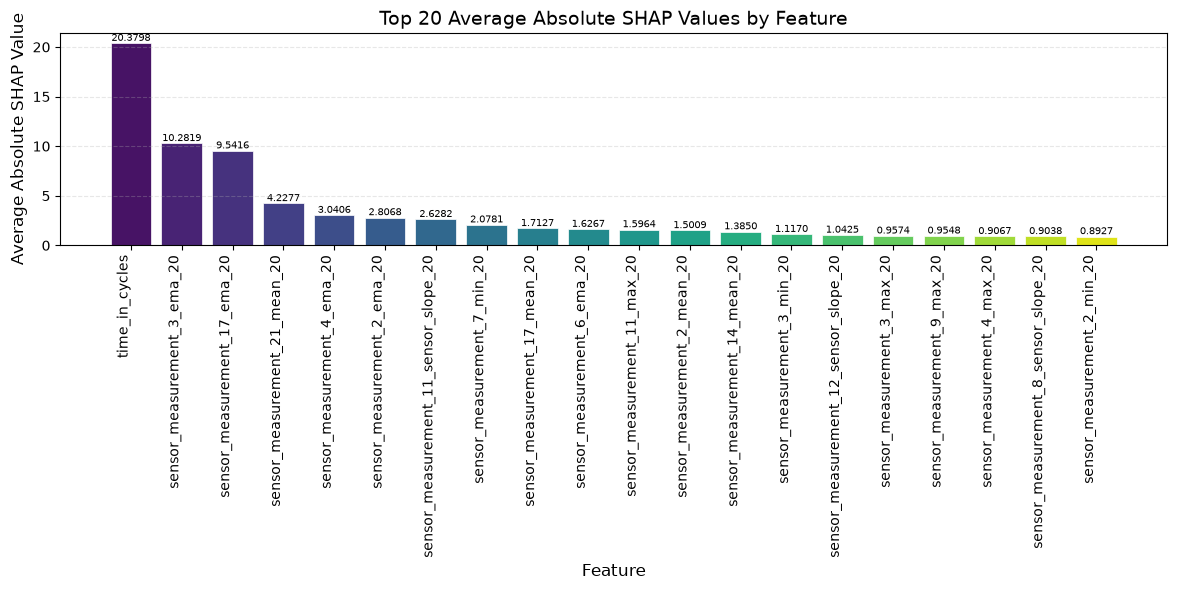

In [235]:
plt.figure(figsize=(12, 6))
colors = sns.color_palette("viridis", len(top_20_avg_shap_value_per_feature))
bars = plt.bar(top_20_avg_shap_value_per_feature.keys(), top_20_avg_shap_value_per_feature.values(), color=colors, edgecolor='white', linewidth=0.5)

for bar in bars: 
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"{height:.4f}",
        ha='center',
        va='bottom',
        fontsize=7
    )

plt.title("Top 20 Average Absolute SHAP Values by Feature", fontsize=14)
plt.xlabel("Feature", fontsize=12)
plt.ylabel("Average Absolute SHAP Value", fontsize=12)
plt.xticks(rotation=90, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

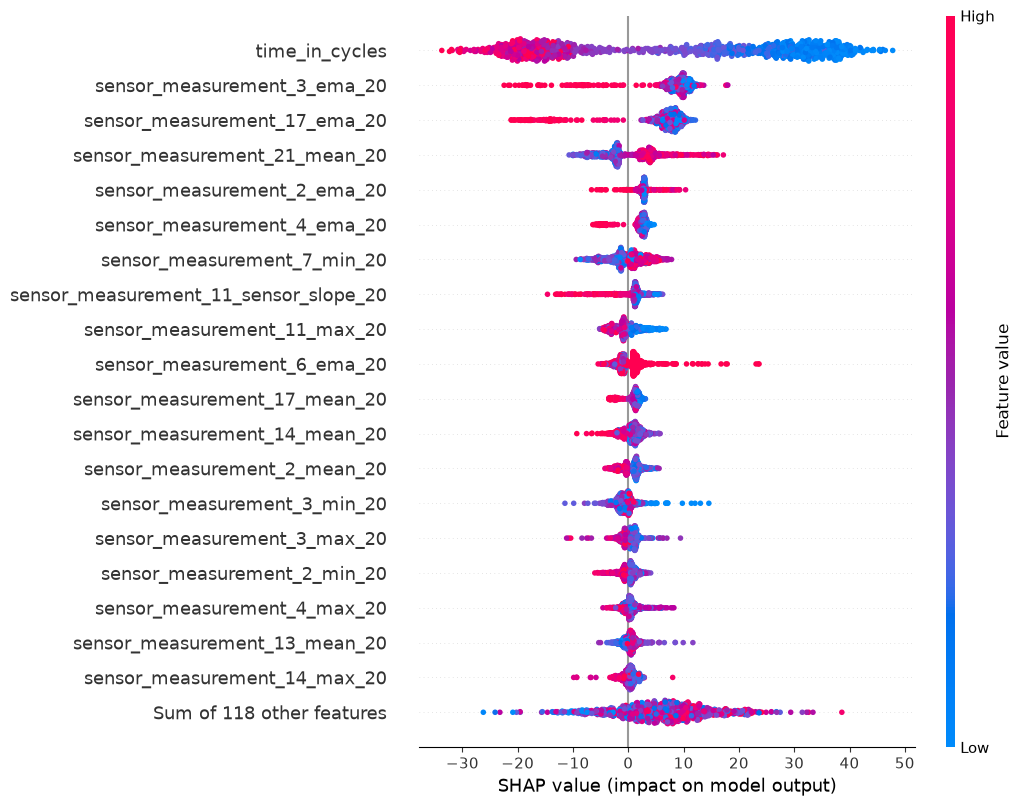

In [236]:
global_sample_mask = observations_to_explain.index.isin(global_sample.index)
global_shap_values = shap_values[global_sample_mask]

shap.plots.beeswarm(
    global_shap_values,
    max_display=20,
)

In [237]:
critical_prediction_mask = observations_to_explain["predicted_rul"] <= 10

critical_shap_values_df = shap_values_df.loc[
    critical_prediction_mask.to_numpy()
].copy()

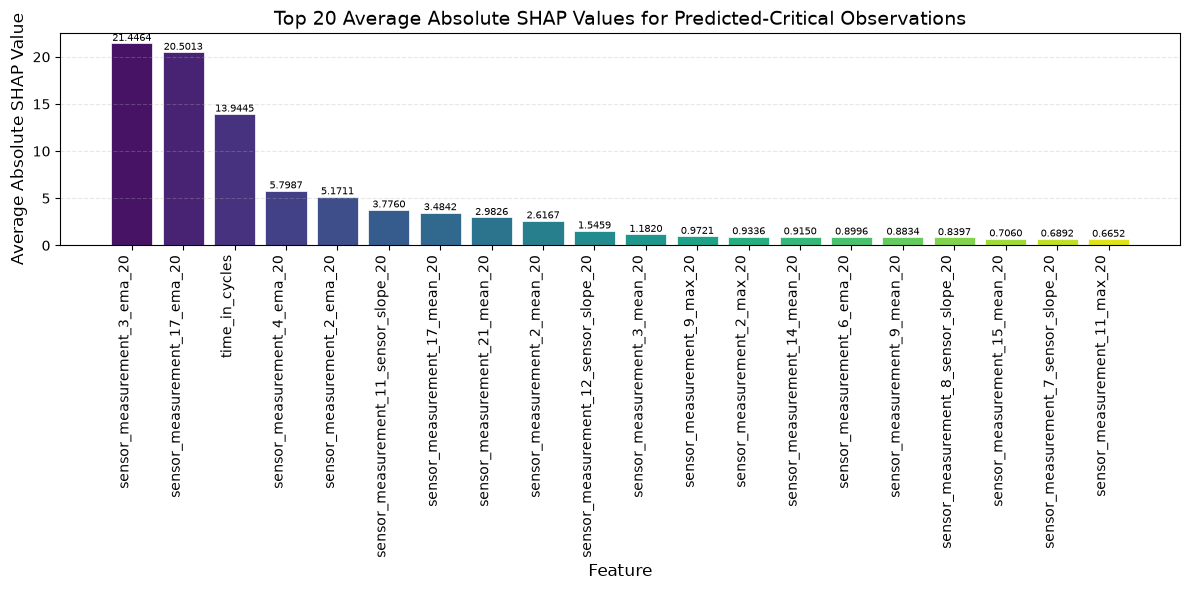

In [238]:
critical_avg_shap_value_per_feature = {}

for column in critical_shap_values_df.columns:
    critical_avg_shap_value_per_feature.update({
        column: float(
            critical_shap_values_df[column].abs().mean()
        )
    })

critical_top_20_avg_shap_value_per_feature = dict(
    heapq.nlargest(
        20,
        critical_avg_shap_value_per_feature.items(),
        key=lambda item: item[1],
    )
)

plt.figure(figsize=(12, 6))

colors = sns.color_palette(
    "viridis",
    len(critical_top_20_avg_shap_value_per_feature),
)

bars = plt.bar(
    critical_top_20_avg_shap_value_per_feature.keys(),
    critical_top_20_avg_shap_value_per_feature.values(),
    color=colors,
    edgecolor="white",
    linewidth=0.5,
)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.4f}",
        ha="center",
        va="bottom",
        fontsize=7,
    )

plt.title(
    "Top 20 Average Absolute SHAP Values for Predicted-Critical Observations",
    fontsize=14,
)
plt.xlabel("Feature", fontsize=12)
plt.ylabel("Average Absolute SHAP Value", fontsize=12)
plt.xticks(rotation=90, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

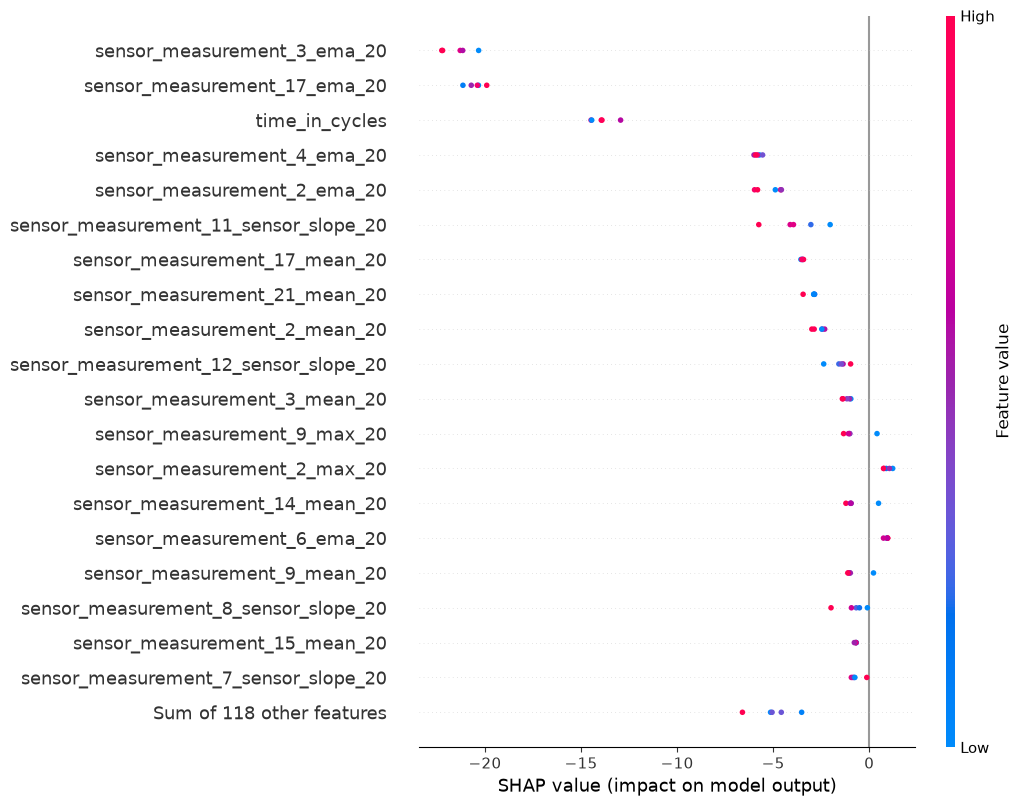

In [239]:
critical_shap_values = shap_values[
    critical_prediction_mask.to_numpy()
]

shap.plots.beeswarm(
    critical_shap_values,
    max_display=20,
)


Correct critical prediction
Engine: 34
Cycle: 203
Actual RUL: 7.0
Predicted RUL: 8.238857765328353
Predicted status: Critical


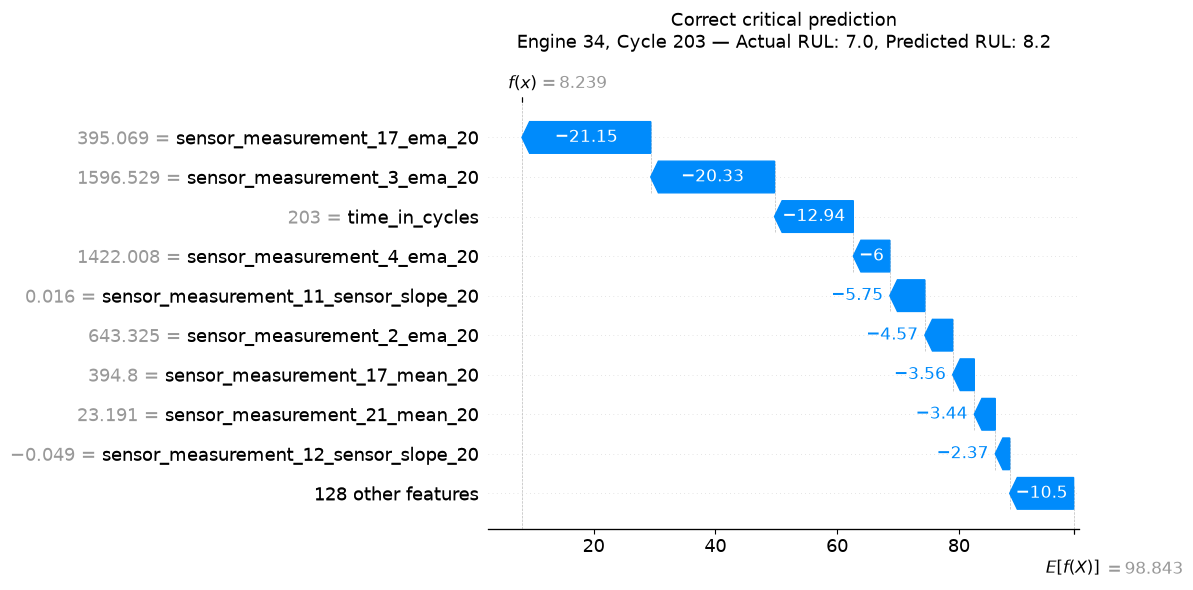


Missed critical observation
Engine: 31
Cycle: 194
Actual RUL: 10.0
Predicted RUL: 12.93821973233738
Predicted status: Warning


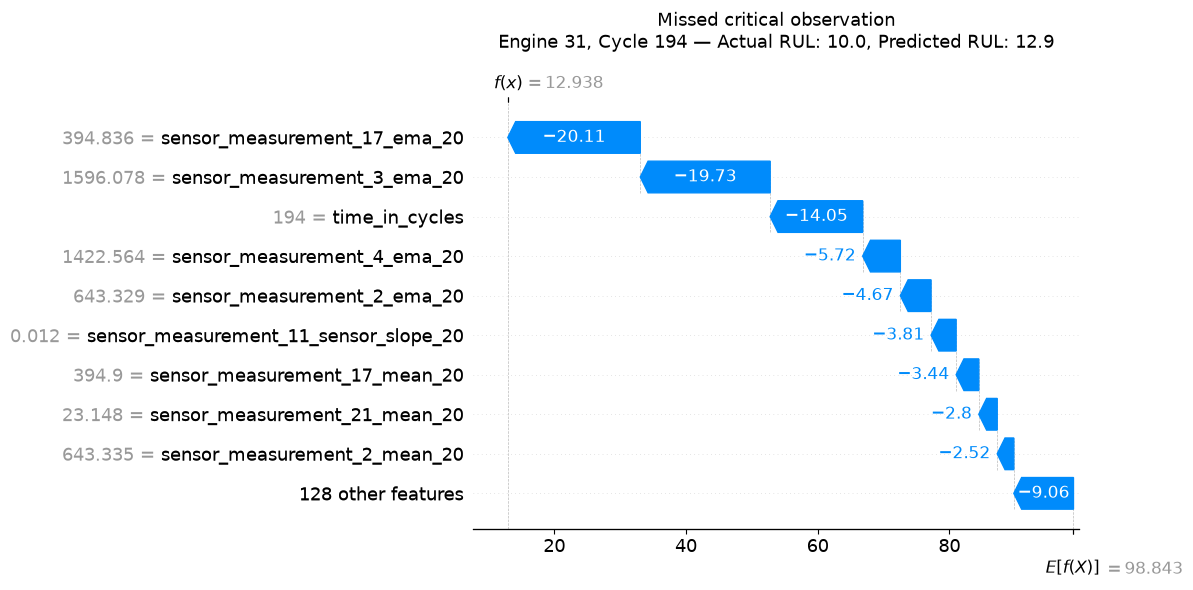


False critical alarm
Engine: 76
Cycle: 204
Actual RUL: 11.0
Predicted RUL: 9.901068575578378
Predicted status: Critical


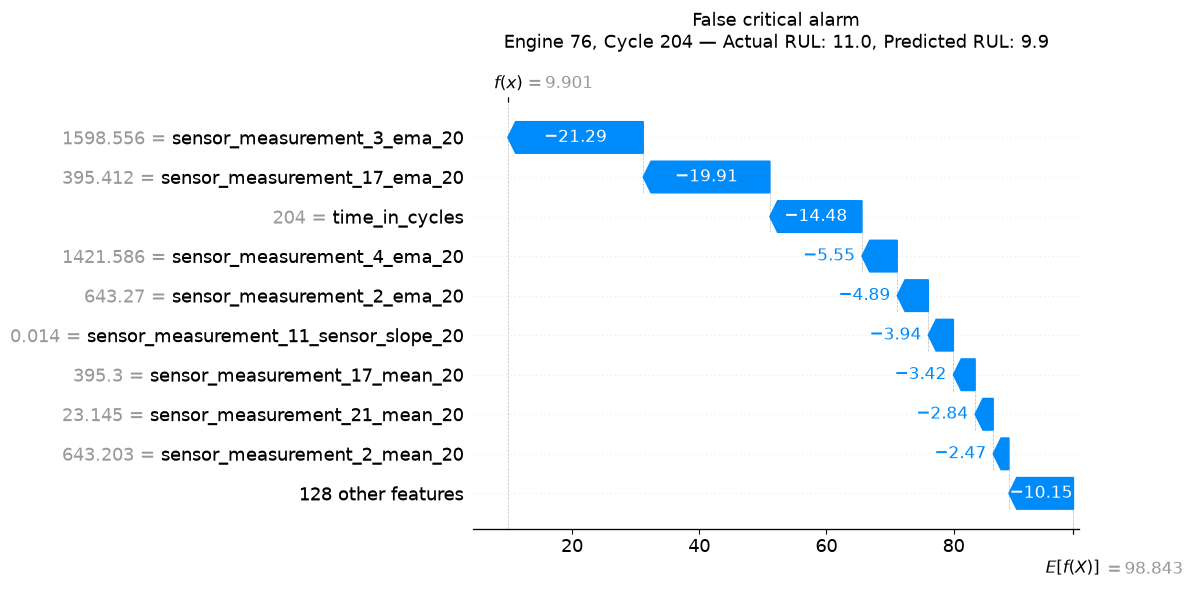


Correct healthy prediction
Engine: 1
Cycle: 20
Actual RUL: 123.0
Predicted RUL: 169.39537555763053
Predicted status: Healthy


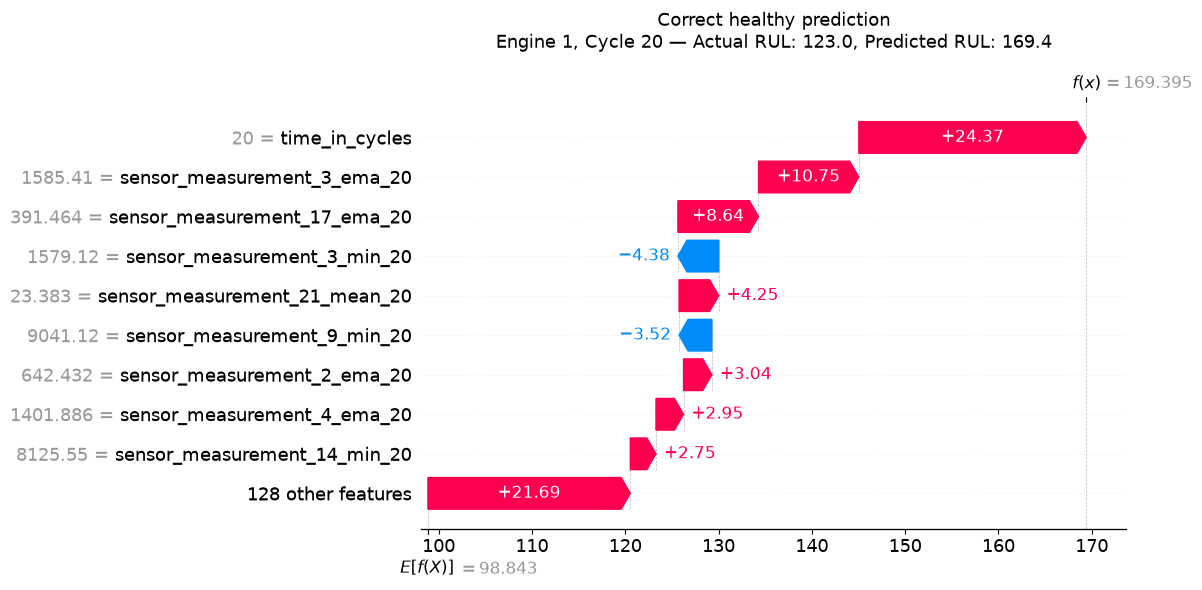

In [240]:
# Create the four groups of observations
correct_critical_rows = observations_to_explain[
    (observations_to_explain["remaining_useful_life"] <= 10)
    & (observations_to_explain["predicted_rul"] <= 10)
]

missed_critical_rows = observations_to_explain[
    (observations_to_explain["remaining_useful_life"] <= 10)
    & (observations_to_explain["predicted_rul"] > 10)
]

false_critical_alarm_rows = observations_to_explain[
    (observations_to_explain["remaining_useful_life"] > 10)
    & (observations_to_explain["predicted_rul"] <= 10)
]

correct_healthy_rows = observations_to_explain[
    (observations_to_explain["remaining_useful_life"] > 30)
    & (observations_to_explain["predicted_rul"] > 30)
]


# Put the four groups together
local_explanation_groups = {
    "Correct critical prediction": correct_critical_rows,
    "Missed critical observation": missed_critical_rows,
    "False critical alarm": false_critical_alarm_rows,
    "Correct healthy prediction": correct_healthy_rows,
}


# Create one local explanation from every group
for explanation_name, candidate_rows in local_explanation_groups.items():

    if candidate_rows.empty:
        print(f"No observations found for: {explanation_name}")
        continue

    selected_observation = candidate_rows.iloc[0]

    observation_index = selected_observation.name

    row_position = observations_to_explain.index.get_loc(
        observation_index
    )

    engine_number = int(
        selected_observation["unit_number"]
    )

    cycle = int(
        selected_observation["time_in_cycles"]
    )

    actual_rul = float(
        selected_observation["remaining_useful_life"]
    )

    predicted_rul = float(
        selected_observation["predicted_rul"]
    )

    if predicted_rul <= 10:
        predicted_status = "Critical"
    elif predicted_rul <= 30:
        predicted_status = "Warning"
    else:
        predicted_status = "Healthy"

    print()
    print(explanation_name)
    print("Engine:", engine_number)
    print("Cycle:", cycle)
    print("Actual RUL:", actual_rul)
    print("Predicted RUL:", predicted_rul)
    print("Predicted status:", predicted_status)

    local_shap_values = shap_values[row_position]

    shap.plots.waterfall(
        local_shap_values,
        max_display=10,
        show=False,
    )

    figure = plt.gcf()
    figure.set_size_inches(12, 6)

    plt.title(
        f"{explanation_name}\n"
        f"Engine {engine_number}, Cycle {cycle} — "
        f"Actual RUL: {actual_rul:.1f}, "
        f"Predicted RUL: {predicted_rul:.1f}",
        fontsize=13,
        pad=20,
    )

    plt.tight_layout()
    plt.show()

In [241]:
processed_test_features_and_predictions["residual"] = processed_test_features_and_predictions["remaining_useful_life"] - processed_test_features_and_predictions["predicted_rul"] 

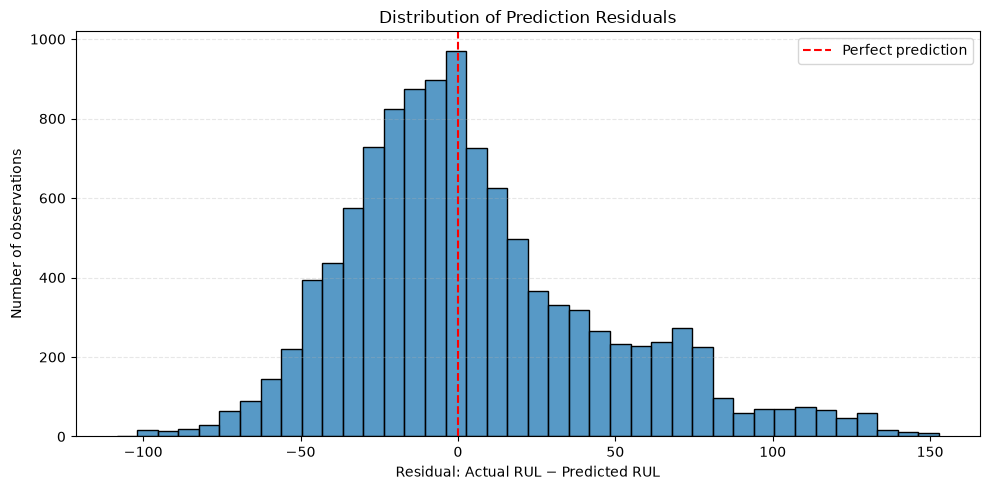

In [242]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=processed_test_features_and_predictions,
    x="residual",
    bins=40, # bins=40 means Divide the complete residual range into 40 approximately equal intervals.
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Perfect prediction",
)

plt.title("Distribution of Prediction Residuals")
plt.xlabel("Residual: Actual RUL − Predicted RUL")
plt.ylabel("Number of observations")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

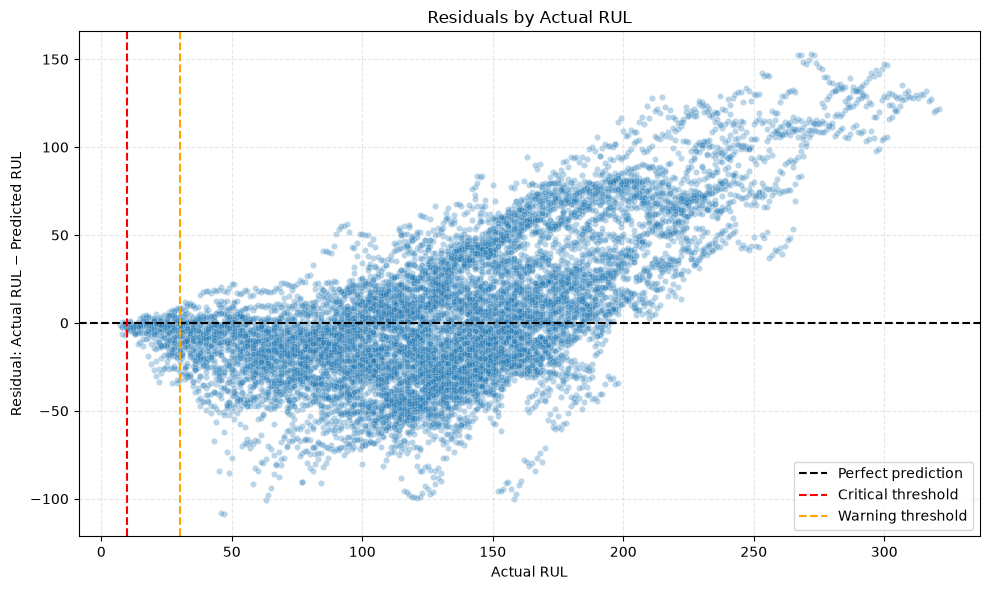

In [243]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=processed_test_features_and_predictions,
    x="remaining_useful_life",
    y="residual",
    alpha=0.3,
    s=20, #s controls the size of every point in the scatter plot:
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    label="Perfect prediction",
)

plt.axvline(
    x=10,
    color="red",
    linestyle="--",
    label="Critical threshold",
)

plt.axvline(
    x=30,
    color="orange",
    linestyle="--",
    label="Warning threshold",
)

plt.title("Residuals by Actual RUL")
plt.xlabel("Actual RUL")
plt.ylabel("Residual: Actual RUL − Predicted RUL")
plt.legend()
plt.grid(linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

In [244]:
# ============================================================
# 1. Prepare the Phase 7 metrics
# ============================================================

residuals = processed_test_features_and_predictions["residual"]

phase_7_metrics = {
    "phase7_mean_residual": float(residuals.mean()),
    "phase7_median_residual": float(residuals.median()),
    "phase7_optimistic_prediction_percentage": float(residuals.lt(0).mean() * 100),
    "phase7_shap_observations": int(len(X_shap)),
    "phase7_predicted_critical_shap_observations": int(len(critical_shap_values)),
}


# ============================================================
# 2. Prepare the importance tables
# ============================================================

native_importance_table = (
    native_importance
    .rename_axis("feature")
    .reset_index()
)

grouped_native_importance_table = (
    native_importance_by_feature
    .rename_axis("input_group")
    .reset_index()
)

permutation_importance_table = (
    permutation_result_df
    .rename_axis("feature")
    .reset_index()
)

grouped_permutation_importance_table = (
    grouped_permutation_importance
    .reset_index()
)

shap_importance_table = pd.DataFrame({
    "feature": avg_shap_value_per_feature.keys(),
    "mean_absolute_shap": avg_shap_value_per_feature.values(),
}).sort_values(
    by="mean_absolute_shap",
    ascending=False,
)

critical_shap_importance_table = pd.DataFrame({
    "feature": critical_avg_shap_value_per_feature.keys(),
    "mean_absolute_shap": critical_avg_shap_value_per_feature.values(),
}).sort_values(
    by="mean_absolute_shap",
    ascending=False,
)


# ============================================================
# 3. Reopen the final model run
# ============================================================

with mlflow.start_run(run_id=source_run_id):

    mlflow.set_tags({
        "phase7_analysis": "explainability_and_error_analysis",
        "explainer_type": "shap_tree_explainer",
        "residual_definition": "actual_rul_minus_predicted_rul",
        "model_version_analyzed": str(model_version),
    })

    mlflow.log_metrics(phase_7_metrics)


    # ========================================================
    # 4. Log the importance tables
    # ========================================================

    mlflow.log_table(
        data=native_importance_table,
        artifact_file="phase_7/tables/native_importance.json",
    )

    mlflow.log_table(
        data=grouped_native_importance_table,
        artifact_file="phase_7/tables/grouped_native_importance.json",
    )

    mlflow.log_table(
        data=permutation_importance_table,
        artifact_file="phase_7/tables/permutation_importance.json",
    )

    mlflow.log_table(
        data=grouped_permutation_importance_table,
        artifact_file="phase_7/tables/grouped_permutation_importance.json",
    )

    mlflow.log_table(
        data=shap_importance_table,
        artifact_file="phase_7/tables/shap_importance.json",
    )

    mlflow.log_table(
        data=critical_shap_importance_table,
        artifact_file="phase_7/tables/critical_shap_importance.json",
    )


    # ========================================================
    # 5. Log the global SHAP bar plot
    # ========================================================

    figure, axis = plt.subplots(figsize=(12, 6))

    axis.bar(
        top_20_avg_shap_value_per_feature.keys(),
        top_20_avg_shap_value_per_feature.values(),
        color=sns.color_palette(
            "viridis",
            len(top_20_avg_shap_value_per_feature),
        ),
    )

    axis.set_title("Top 20 Average Absolute SHAP Values")
    axis.set_xlabel("Feature")
    axis.set_ylabel("Average Absolute SHAP Value")
    axis.tick_params(axis="x", rotation=90)
    axis.grid(axis="y", linestyle="--", alpha=0.3)

    figure.tight_layout()

    mlflow.log_figure(
        figure,
        "phase_7/plots/global_shap_bar.png",
    )

    plt.close(figure)


    # ========================================================
    # 6. Log the global SHAP beeswarm plot
    # ========================================================

    shap.plots.beeswarm(
        global_shap_values,
        max_display=20,
        show=False,
    )

    figure = plt.gcf()
    figure.set_size_inches(12, 6)
    figure.tight_layout()

    mlflow.log_figure(
        figure,
        "phase_7/plots/global_shap_beeswarm.png",
    )

    plt.close(figure)


    # ========================================================
    # 7. Log the critical SHAP bar plot
    # ========================================================

    figure, axis = plt.subplots(figsize=(12, 6))

    axis.bar(
        critical_top_20_avg_shap_value_per_feature.keys(),
        critical_top_20_avg_shap_value_per_feature.values(),
        color=sns.color_palette(
            "viridis",
            len(critical_top_20_avg_shap_value_per_feature),
        ),
    )

    axis.set_title(
        "Top 20 SHAP Values for Predicted-Critical Observations"
    )
    axis.set_xlabel("Feature")
    axis.set_ylabel("Average Absolute SHAP Value")
    axis.tick_params(axis="x", rotation=90)
    axis.grid(axis="y", linestyle="--", alpha=0.3)

    figure.tight_layout()

    mlflow.log_figure(
        figure,
        "phase_7/plots/critical_shap_bar.png",
    )

    plt.close(figure)


    # ========================================================
    # 8. Log the critical SHAP beeswarm plot
    # ========================================================

    shap.plots.beeswarm(
        critical_shap_values,
        max_display=20,
        show=False,
    )

    figure = plt.gcf()
    figure.set_size_inches(12, 6)
    figure.tight_layout()

    mlflow.log_figure(
        figure,
        "phase_7/plots/critical_shap_beeswarm.png",
    )

    plt.close(figure)


    # ========================================================
    # 9. Log the residual histogram
    # ========================================================

    figure, axis = plt.subplots(figsize=(10, 5))

    sns.histplot(
        data=processed_test_features_and_predictions,
        x="residual",
        bins=40,
        ax=axis,
    )

    axis.axvline(
        x=0,
        color="red",
        linestyle="--",
        label="Perfect prediction",
    )

    axis.set_title("Distribution of Prediction Residuals")
    axis.set_xlabel("Residual: Actual RUL − Predicted RUL")
    axis.set_ylabel("Number of observations")
    axis.legend()
    axis.grid(axis="y", linestyle="--", alpha=0.3)

    figure.tight_layout()

    mlflow.log_figure(
        figure,
        "phase_7/plots/residual_distribution.png",
    )

    plt.close(figure)


    # ========================================================
    # 10. Log residual versus actual RUL
    # ========================================================

    figure, axis = plt.subplots(figsize=(10, 6))

    sns.scatterplot(
        data=processed_test_features_and_predictions,
        x="remaining_useful_life",
        y="residual",
        alpha=0.3,
        s=20,
        ax=axis,
    )

    axis.axhline(
        y=0,
        color="black",
        linestyle="--",
        label="Perfect prediction",
    )

    axis.axvline(
        x=10,
        color="red",
        linestyle="--",
        label="Critical threshold",
    )

    axis.axvline(
        x=30,
        color="orange",
        linestyle="--",
        label="Warning threshold",
    )

    axis.set_title("Residuals by Actual RUL")
    axis.set_xlabel("Actual RUL")
    axis.set_ylabel("Residual: Actual RUL − Predicted RUL")
    axis.legend()
    axis.grid(linestyle="--", alpha=0.3)

    figure.tight_layout()

    mlflow.log_figure(
        figure,
        "phase_7/plots/residuals_by_actual_rul.png",
    )

    plt.close(figure)


    # ========================================================
    # 11. Log the four local waterfall explanations
    # ========================================================

    local_explanation_records = []

    for explanation_name, candidate_rows in local_explanation_groups.items():

        if candidate_rows.empty:
            continue

        selected_observation = candidate_rows.iloc[0]
        observation_index = selected_observation.name
        row_position = observations_to_explain.index.get_loc(observation_index)

        engine_number = int(selected_observation["unit_number"])
        cycle = int(selected_observation["time_in_cycles"])
        actual_rul = float(selected_observation["remaining_useful_life"])
        predicted_rul = float(selected_observation["predicted_rul"])

        if predicted_rul <= 10:
            predicted_status = "Critical"
        elif predicted_rul <= 30:
            predicted_status = "Warning"
        else:
            predicted_status = "Healthy"

        local_explanation_records.append({
            "explanation_type": explanation_name,
            "engine_number": engine_number,
            "cycle": cycle,
            "actual_rul": actual_rul,
            "predicted_rul": predicted_rul,
            "predicted_status": predicted_status,
        })

        shap.plots.waterfall(
            shap_values[row_position],
            max_display=10,
            show=False,
        )

        figure = plt.gcf()
        figure.set_size_inches(12, 6)

        plt.title(
            f"{explanation_name}\n"
            f"Engine {engine_number}, Cycle {cycle} — "
            f"Actual RUL: {actual_rul:.1f}, "
            f"Predicted RUL: {predicted_rul:.1f}",
            fontsize=13,
            pad=20,
        )

        figure.tight_layout()

        figure_name = (
            explanation_name
            .lower()
            .replace(" ", "_")
        )

        mlflow.log_figure(
            figure,
            f"phase_7/plots/local_{figure_name}.png",
        )

        plt.close(figure)


    # Log the information associated with the waterfall plots
    local_explanation_table = pd.DataFrame(
        local_explanation_records
    )

    mlflow.log_table(
        data=local_explanation_table,
        artifact_file="phase_7/tables/local_explanations.json",
    )


    # ========================================================
    # 12. Log the completed notebook
    # ========================================================

    notebook_path = (
        project_root
        / "notebooks"
        / "08_explainability_and_error_analysis.ipynb"
    )

    mlflow.log_artifact(
        str(notebook_path),
        artifact_path="phase_7/notebook",
    )

    mlflow.set_tag(
        "phase7_analysis_complete",
        "true",
    )


print(
    "Phase 7 analysis logged to MLflow run:",
    source_run_id,
)

Phase 7 analysis logged to MLflow run: 360c5414c7d841a38bcf9480521a7b59
